In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load Netflix dataset
df = pd.read_csv('/content/netflix_data.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [17]:
# Remove duplicate
df = df.drop_duplicates(subset=['show_id'])
# Fill missing text values
text_columns = [
    'title', 'director', 'cast', 'country',
    'listed_in', 'description'
]
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].fillna('')
# Keep movies only
movies = df[df['type'] == 'Movie'].copy()
movies = movies.reset_index(drop=True)
print("Total Netflix titles:", len(df))
print("Movies available:", len(movies))
print("\nSample movie titles:")
display(movies[['title', 'listed_in', 'description']].head())

Total Netflix titles: 8807
Movies available: 6131

Sample movie titles:


,title,listed_in,description
0,Dick Johnson Is Dead,Documentaries,"As her father nears the end of his life, filmm..."
1,My Little Pony: A New Generation,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
2,Sankofa,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
3,The Starling,"Comedies, Dramas",A woman adjusting to life after a loss contend...
4,Je Suis Karl,"Dramas, International Movies",After most of her family is murdered in a terr...


In [18]:
movies['combined_features'] = (
    movies['listed_in'] + ' ' +
    movies['director'] + ' ' +
    movies['cast'] + ' ' +
    movies['description']
)
print("Movie features prepared!")
display(movies[['title', 'combined_features']].head())

Movie features prepared!


,title,combined_features
0,Dick Johnson Is Dead,Documentaries Kirsten Johnson As her father n...
1,My Little Pony: A New Generation,"Children & Family Movies Robert Cullen, José L..."
2,Sankofa,"Dramas, Independent Movies, International Movi..."
3,The Starling,"Comedies, Dramas Theodore Melfi Melissa McCart..."
4,Je Suis Karl,"Dramas, International Movies Christian Schwoch..."


In [19]:
# Convert text into numerical features
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(
    movies['combined_features']
)
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Movie features converted successfully!")

TF-IDF matrix shape: (6131, 40519)
Movie features converted successfully!


In [20]:
# Create a mapping from movie titles to their indices
indices = pd.Series(
    movies.index,
    index=movies['title'].str.lower()
).drop_duplicates()
def recommend_movies(title, num_recommendations=5):
    title = title.lower().strip()
    if title not in indices:
        matches = movies[
            movies['title'].str.contains(
                title, case=False, na=False, regex=False
            )
        ]['title'].head(10).tolist()
        if matches:
            print("Title not found exactly. Similar titles:")
            for match in matches:
                print("-", match)
        else:
            print("Movie not found. Try another title.")
        return
    idx = indices[title]
    similarity_scores = list(enumerate(cosine_sim[idx]))
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )
    # Skip the movie itself
    similarity_scores = similarity_scores[1:num_recommendations + 1]
    movie_indices = [i[0] for i in similarity_scores]
    return movies.iloc[movie_indices][
        ['title', 'listed_in', 'release_year', 'description']
    ]

In [22]:
# Calculate cosine similarity matrix
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Get movie recommendations
recommend_movies("The Conjuring")

,title,listed_in,release_year,description
850,The Conjuring 2,Horror Movies,2016,After her daughter unwittingly releases a male...
1461,The Long Dumb Road,"Comedies, Independent Movies",2018,"Bound for art school, a sheltered student gets..."
735,Insidious,"Horror Movies, Thrillers",2010,"A family moves into a new home, where their so..."
4641,Haunting on Fraternity Row,"Horror Movies, Independent Movies",2018,When a fraternity's last big luau serves up ho...
2196,Eli,Horror Movies,2019,"With his desperate parents in tow, an 11-year-..."


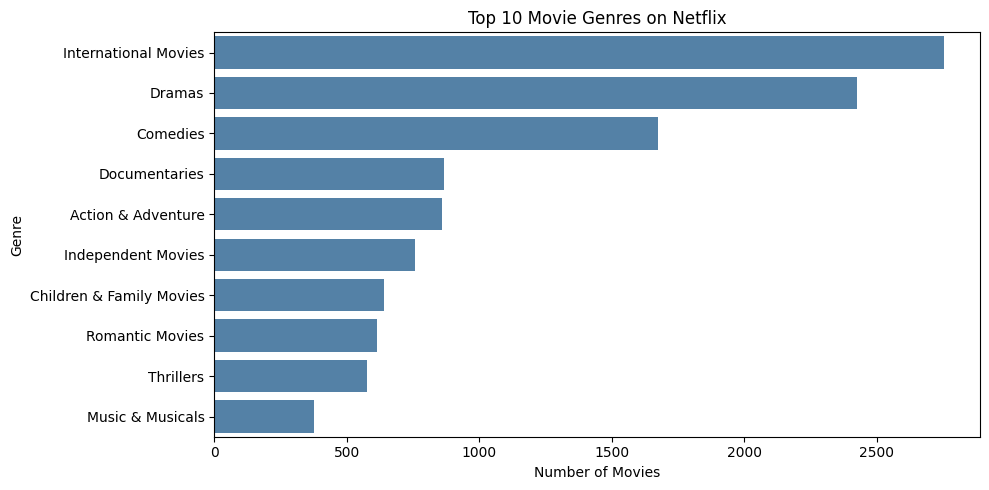

In [23]:
# Display the top 10 most common movie genres
genre_counts = (
    movies['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color='steelblue')

plt.title('Top 10 Movie Genres on Netflix')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

In [24]:
print("MOVIE RECOMMENDATION SYSTEM")
print("-" * 35)
print("Total titles in dataset:", len(df))
print("Movies analyzed:", len(movies))
print("Unique movie titles:", movies['title'].nunique())
print("Number of features:", tfidf_matrix.shape[1])

print("\nSample recommendations:")
display(recommend_movies("The Conjuring"))

MOVIE RECOMMENDATION SYSTEM
-----------------------------------
Total titles in dataset: 8807
Movies analyzed: 6131
Unique movie titles: 6131
Number of features: 40519

Sample recommendations:


,title,listed_in,release_year,description
850,The Conjuring 2,Horror Movies,2016,After her daughter unwittingly releases a male...
1461,The Long Dumb Road,"Comedies, Independent Movies",2018,"Bound for art school, a sheltered student gets..."
735,Insidious,"Horror Movies, Thrillers",2010,"A family moves into a new home, where their so..."
4641,Haunting on Fraternity Row,"Horror Movies, Independent Movies",2018,When a fraternity's last big luau serves up ho...
2196,Eli,Horror Movies,2019,"With his desperate parents in tow, an 11-year-..."
